# Analyzing Amazon EC2 Instance Costs
This notebook follows both parts of **Activity – Analysing EC2 Instances** using
the supplied `ec2dataset.csv` (861 rows, 11 columns). Run cells from top to bottom
with **Shift+Enter**. It is independent of the Streamlit app: no app files or helper
modules are imported. Keep the notebook beside the CSV, or edit `file_path` below.

Part 1 explores prices, missing values, IQR outliers, reserved savings and instance
families. Part 2 trains the specified linear regression with memory and vCPUs,
using an 80/20 split and `random_state=42`. As requested, on-demand cost outliers
are excluded from training with training-only 1.5 × IQR bounds. The test set remains intact.

All prices describe the supplied dataset. Its AWS region, capture date and reservation
terms are unspecified. Missing prices remain missing, rather than being treated as zero.


## Part 1 Step 1 — Install dependencies
This cell checks the active notebook environment and installs only missing packages. Internet access is needed if a package must be installed.


In [1]:
import importlib.util
import subprocess
import sys
packages = {"pandas": "pandas>=2.2,<4", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4", "seaborn": "seaborn>=0.13,<0.14",
            "sklearn": "scikit-learn>=1.5,<2"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("All analysis dependencies are available in", sys.executable)


All analysis dependencies are available in C:\Users\madus\Downloads\cloud-economics-ml\.venv\Scripts\python.exe


## Part 1 Step 2 — Load and explore the dataset
Change the path if the CSV is stored elsewhere. The preview and information show original values before cleaning.


In [2]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
file_path = Path("ec2dataset.csv")
if not file_path.exists():
    raise FileNotFoundError("Set file_path to the full path of your ec2dataset.csv.")
raw_data = pd.read_csv(file_path)
data = raw_data.copy()
cost_columns = ["On Demand", "Linux Reserved cost", "Linux Spot Minimum cost",
                "Windows On Demand cost", "Windows Reserved cost"]
features = ["Instance Memory", "vCPUs"]
required = ["Name", "API Name", *features, "Instance Storage", "Network Performance", *cost_columns]
missing_columns = sorted(set(required) - set(data.columns))
if missing_columns:
    raise ValueError("Missing required columns: " + ", ".join(missing_columns))
print(f"Rows: {len(data)}, columns: {len(data.columns)} (activity describes 861 × 11)")
data.info()
display(data.head())


Rows: 861, columns: 11 (activity describes 861 × 11)
<class 'pandas.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Name                     861 non-null    str  
 1   API Name                 861 non-null    str  
 2   Instance Memory          861 non-null    str  
 3   vCPUs                    861 non-null    str  
 4   Instance Storage         861 non-null    str  
 5   Network Performance      861 non-null    str  
 6   On Demand                861 non-null    str  
 7   Linux Reserved cost      861 non-null    str  
 8   Linux Spot Minimum cost  861 non-null    str  
 9   Windows On Demand cost   861 non-null    str  
 10  Windows Reserved cost    861 non-null    str  
dtypes: str(11)
memory usage: 200.3 KB


,Name,API Name,Instance Memory,vCPUs,Instance Storage,Network Performance,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
0,T4G Nano,t4g.nano,0.5 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,$0.0042 hourly,$0.0026 hourly,$0.0014 hourly,unavailable,unavailable
1,T3A Nano,t3a.nano,0.5 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,$0.0047 hourly,$0.0029 hourly,$0.0014 hourly,$0.0093 hourly,$0.0075 hourly
2,T3 Nano,t3.nano,0.5 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,$0.0052 hourly,$0.0033 hourly,$0.0007 hourly,$0.0098 hourly,$0.0079 hourly
3,T2 Nano,t2.nano,0.5 GiB,1 vCPUs ...,EBS only,Low to Moderate,$0.0058 hourly,$0.0036 hourly,unavailable,$0.0081 hourly,$0.0059 hourly
4,T4G Micro,t4g.micro,1.0 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,$0.0084 hourly,$0.0053 hourly,$0.0024 hourly,unavailable,unavailable


## Part 1 Step 3 — Clean the cost columns
Remove currency symbols, commas, whitespace and the word hourly. Unavailable values become NaN. The original data is retained in `raw_data`.


In [3]:
for column in cost_columns:
    numeric_text = data[column].astype("string").str.replace(r"[$,\s]|hourly", "", regex=True)
    data[column] = pd.to_numeric(numeric_text, errors="coerce")
data[cost_columns] = data[cost_columns].replace([np.inf, -np.inf], np.nan)
display(data[cost_columns].isna().sum().rename("Missing rows").to_frame())
display(data.head())


,Missing rows
On Demand,20
Linux Reserved cost,24
Linux Spot Minimum cost,39
Windows On Demand cost,263
Windows Reserved cost,266


,Name,API Name,Instance Memory,vCPUs,Instance Storage,Network Performance,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
0,T4G Nano,t4g.nano,0.5 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0042,0.0026,0.0014,<NA>,<NA>
1,T3A Nano,t3a.nano,0.5 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0047,0.0029,0.0014,0.0093,0.0075
2,T3 Nano,t3.nano,0.5 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0052,0.0033,0.0007,0.0098,0.0079
3,T2 Nano,t2.nano,0.5 GiB,1 vCPUs ...,EBS only,Low to Moderate,0.0058,0.0036,<NA>,0.0081,0.0059
4,T4G Micro,t4g.micro,1.0 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0084,0.0053,0.0024,<NA>,<NA>


## Part 1 Step 4 — Summarize costs
Count excludes missing prices. All other statistics are calculated from the available prices in each column.


In [4]:
cost_summary = data[cost_columns].describe()
display(cost_summary)


,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
count,841.0,837.0,822.0,598.0,595.0
mean,5.188935,3.200449,0.725993,8.561024,6.297091
std,22.728064,13.904896,1.775821,30.135524,20.088637
min,0.0042,0.0026,0.0007,0.0081,0.0059
25%,0.34,0.2159,0.10365,0.7269,0.58895
50%,1.5631,0.9848,0.3726,3.196,2.5583
75%,4.118,2.6359,0.949725,8.14325,6.371
max,407.68,251.2308,45.6302,448.896,292.4468


## Part 1 Step 5 — Visualize pricing distributions


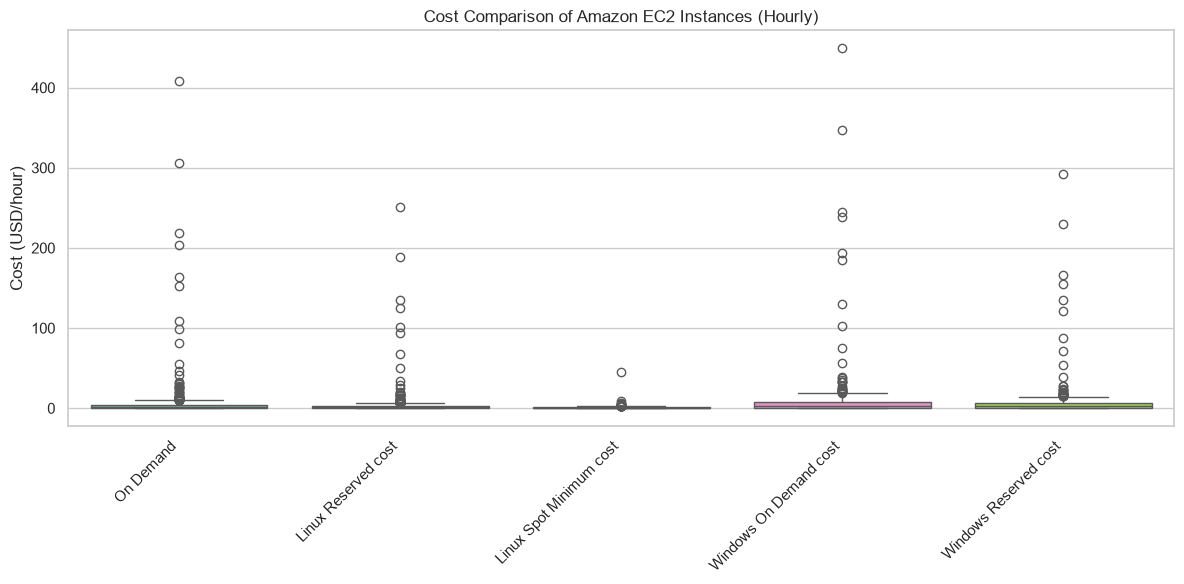

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=data[cost_columns], palette="Set2", ax=ax)
ax.set(title="Cost Comparison of Amazon EC2 Instances (Hourly)", ylabel="Cost (USD/hour)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Part 1 Step 6 — Identify potential on-demand outliers
Use the activity's 1.5 × IQR rule. A flag is a statistical observation; it does not establish that a price is incorrect.


In [6]:
def detect_outliers(column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return data[(data[column] < lower_bound) | (data[column] > upper_bound)]

q1, q3 = data["On Demand"].quantile([0.25, 0.75])
iqr = q3 - q1
print(f"Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}")
print(f"Bounds: {q1 - 1.5 * iqr:.4f} to {q3 + 1.5 * iqr:.4f} USD/hour")
outliers_on_demand = detect_outliers("On Demand")
print(f"Potential on-demand outliers: {len(outliers_on_demand)}")
display(outliers_on_demand)


Q1=0.3400, Q3=4.1180, IQR=3.7780
Bounds: -5.3270 to 9.7850 USD/hour
Potential on-demand outliers: 66


,Name,API Name,Instance Memory,vCPUs,Instance Storage,Network Performance,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
775,C7A Metal-48xl,c7a.metal-48xl,384.0 GiB,192 vCPUs,EBS only,50 Gigabit,9.8534,6.518,1.4675,18.6854,15.35
776,C7A 48xlarge,c7a.48xlarge,384.0 GiB,192 vCPUs,EBS only,50 Gigabit,9.8534,6.518,2.7641,18.6854,15.35
777,X2IDN 24xlarge,x2idn.24xlarge,1536.0 GiB,96 vCPUs,2850 GB (2 * 1425 GB NVMe SSD),75 Gigabit,10.0035,6.1551,1.1498,14.4195,10.5711
778,X2IEZN 12xlarge,x2iezn.12xlarge,1536.0 GiB,48 vCPUs,EBS only,100 Gigabit,10.008,6.1614,3.0475,12.216,8.3694
779,X2IEZN Metal,x2iezn.metal,1536.0 GiB,48 vCPUs,EBS only,100 Gigabit,10.008,6.1614,1.8874,12.216,8.3694
...,...,...,...,...,...,...,...,...,...,...,...
836,U-18TB1 112xlarge,u-18tb1.112xlarge,18432.0 GiB,448 vCPUs,EBS only,100 Gigabit,163.8,100.9409,<NA>,184.408,121.5489
837,U7IN-16TB 224xlarge,u7in-16tb.224xlarge,16384.0 GiB,896 vCPUs,EBS only,200 Gigabit,203.84,125.6154,<NA>,245.056,166.8314
838,U-24TB1 112xlarge,u-24tb1.112xlarge,24576.0 GiB,448 vCPUs,EBS only,100 Gigabit,218.4,134.5879,<NA>,239.008,155.1959
839,U7IN-24TB 224xlarge,u7in-24tb.224xlarge,24576.0 GiB,896 vCPUs,EBS only,200 Gigabit,305.76,188.4231,<NA>,346.976,229.6391


## Part 1 Step 7 — Compare reserved and on-demand costs
The first table reproduces the activity's ten cheapest instances with both prices. Savings are calculated for each matched instance, with zero on-demand values excluded from percentage division.


In [7]:
cost_comparison = data[["Name", "On Demand", "Linux Reserved cost"]].dropna().sort_values("On Demand").copy()
display(cost_comparison.head(10))
cost_comparison["Savings USD/hour"] = cost_comparison["On Demand"] - cost_comparison["Linux Reserved cost"]
cost_comparison["Savings percent"] = 100 * cost_comparison["Savings USD/hour"] / cost_comparison["On Demand"].replace(0, np.nan)
display(cost_comparison.head(10))
print(f"Median reserved savings: {cost_comparison['Savings percent'].median():.2f}% across {len(cost_comparison)} comparable rows")


,Name,On Demand,Linux Reserved cost
0,T4G Nano,0.0042,0.0026
1,T3A Nano,0.0047,0.0029
2,T3 Nano,0.0052,0.0033
3,T2 Nano,0.0058,0.0036
4,T4G Micro,0.0084,0.0053
5,T3A Micro,0.0094,0.0059
6,T3 Micro,0.0104,0.0065
7,T2 Micro,0.0116,0.0072
8,T4G Small,0.0168,0.0105
9,T3A Small,0.0188,0.0118


,Name,On Demand,Linux Reserved cost,Savings USD/hour,Savings percent
0,T4G Nano,0.0042,0.0026,0.0016,38.095238
1,T3A Nano,0.0047,0.0029,0.0018,38.297872
2,T3 Nano,0.0052,0.0033,0.0019,36.538462
3,T2 Nano,0.0058,0.0036,0.0022,37.931034
4,T4G Micro,0.0084,0.0053,0.0031,36.904762
5,T3A Micro,0.0094,0.0059,0.0035,37.234043
6,T3 Micro,0.0104,0.0065,0.0039,37.5
7,T2 Micro,0.0116,0.0072,0.0044,37.931034
8,T4G Small,0.0168,0.0105,0.0063,37.5
9,T3A Small,0.0188,0.0118,0.007,37.234043


Median reserved savings: 36.99% across 837 comparable rows


### Compare costs for specific capacity needs
Edit the minimum memory and CPU values. CPU counts and memory indicate capacity, while architecture, burst limits, storage and networking also affect actual workload performance.


In [8]:
memory_gib = pd.to_numeric(data["Instance Memory"].astype("string").str.replace(r"\s*GiB\s*", "", regex=True).str.replace(",", "", regex=False), errors="coerce")
cpu_count = pd.to_numeric(data["vCPUs"].astype("string").str.extract(r"(\d+)", expand=False), errors="coerce")
minimum_memory_gib = 4.0
minimum_vcpus = 2
suitable_instances = data.loc[(memory_gib >= minimum_memory_gib) & (cpu_count >= minimum_vcpus)].dropna(subset=["On Demand"]).sort_values("On Demand")
display(suitable_instances.head(10))


,Name,API Name,Instance Memory,vCPUs,Instance Storage,Network Performance,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
14,T4G Medium,t4g.medium,4.0 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0336,0.0211,0.009,<NA>,<NA>
17,T3A Medium,t3a.medium,4.0 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0376,0.0236,0.0116,0.056,0.042
22,T3 Medium,t3.medium,4.0 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0416,0.0261,0.0127,0.06,0.0445
28,T2 Medium,t2.medium,4.0 GiB,2 vCPUs ...,EBS only,Low to Moderate,0.0464,0.0287,0.0121,0.0644,0.0467
30,A1 Large,a1.large,4.0 GiB,2 vCPUs,EBS only,Up to 10 Gigabit,0.051,0.0321,0.0326,<NA>,<NA>
39,T4G Large,t4g.large,8.0 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0672,0.0421,0.0143,<NA>,<NA>
41,C6G Large,c6g.large,4.0 GiB,2 vCPUs,EBS only,Up to 10 Gigabit,0.068,0.0428,0.0201,<NA>,<NA>
42,C7G Large,c7g.large,4.0 GiB,2 vCPUs,EBS only,Up to 12.5 Gigabit,0.0725,0.0478,0.026,<NA>,<NA>
43,T3A Large,t3a.large,8.0 GiB,2 vCPUs ...,EBS only,Up to 5 Gigabit,0.0752,0.0471,0.0201,0.1028,0.0747
45,C6A Large,c6a.large,4.0 GiB,2 vCPUs,EBS only,Up to 12.5 Gigabit,0.0765,0.0506,0.0236,0.1685,0.1426


### Conclusions from the analysis
These statements are calculated from your CSV, rather than assumed AWS pricing trends.


In [9]:
priced = data.dropna(subset=["On Demand"])
if not priced.empty:
    lowest = priced.loc[priced["On Demand"].idxmin()]
    print(f"Lowest listed Linux on-demand price: {lowest['API Name']} at ${lowest['On Demand']:.4f}/hour.")
    print(f"The IQR rule flags {len(outliers_on_demand)} of {len(priced)} available on-demand prices.")
print(f"The median matched Linux reserved discount is {cost_comparison['Savings percent'].median():.2f}%.")
print("Compare workload requirements and reservation terms before selecting an instance.")
print("Large or specialized instances may legitimately appear as IQR outliers.")


Lowest listed Linux on-demand price: t4g.nano at $0.0042/hour.
The IQR rule flags 66 of 841 available on-demand prices.
The median matched Linux reserved discount is 36.99%.
Compare workload requirements and reservation terms before selecting an instance.
Large or specialized instances may legitimately appear as IQR outliers.


## Part 1 Step 8 — Filter and compare instance families
This preserves the activity's Name prefix filter. Its T3 selection includes T3A instances. An additional exact API family comparison below separates T3 and T3A.


In [10]:
def filter_instance_family(family):
    return data[data["Name"].astype("string").str.startswith(family, na=False)]

t2_instances = filter_instance_family("T2")
t3_instances = filter_instance_family("T3")
t2_summary = t2_instances[cost_columns].describe()
t3_summary = t3_instances[cost_columns].describe()
print(f"T2 prefix: {len(t2_instances)} instances")
display(t2_summary)
print(f"T3 prefix (including T3A): {len(t3_instances)} instances")
display(t3_summary)


T2 prefix: 7 instances


,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
count,7.0,7.0,6.0,7.0,7.0
mean,0.1052,0.0652,0.026233,0.128757,0.088786
std,0.13306,0.082432,0.023299,0.154409,0.103796
min,0.0058,0.0036,0.0019,0.0081,0.0059
25%,0.0173,0.0108,0.0085,0.0241,0.0177
50%,0.0464,0.0287,0.01995,0.0644,0.0467
75%,0.1392,0.08625,0.0467,0.1737,0.12075
max,0.3712,0.23,0.0553,0.4332,0.292


T3 prefix (including T3A): 14 instances


,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
count,14.0,14.0,14.0,14.0,14.0
mean,0.089807,0.0563,0.026436,0.132521,0.099014
std,0.109328,0.068537,0.032506,0.158461,0.11771
min,0.0047,0.0029,0.0007,0.0093,0.0075
25%,0.0125,0.007825,0.003875,0.024,0.019325
50%,0.0396,0.02485,0.01215,0.058,0.04325
75%,0.1336,0.083775,0.033175,0.1957,0.145875
max,0.3328,0.2086,0.1009,0.48,0.3558


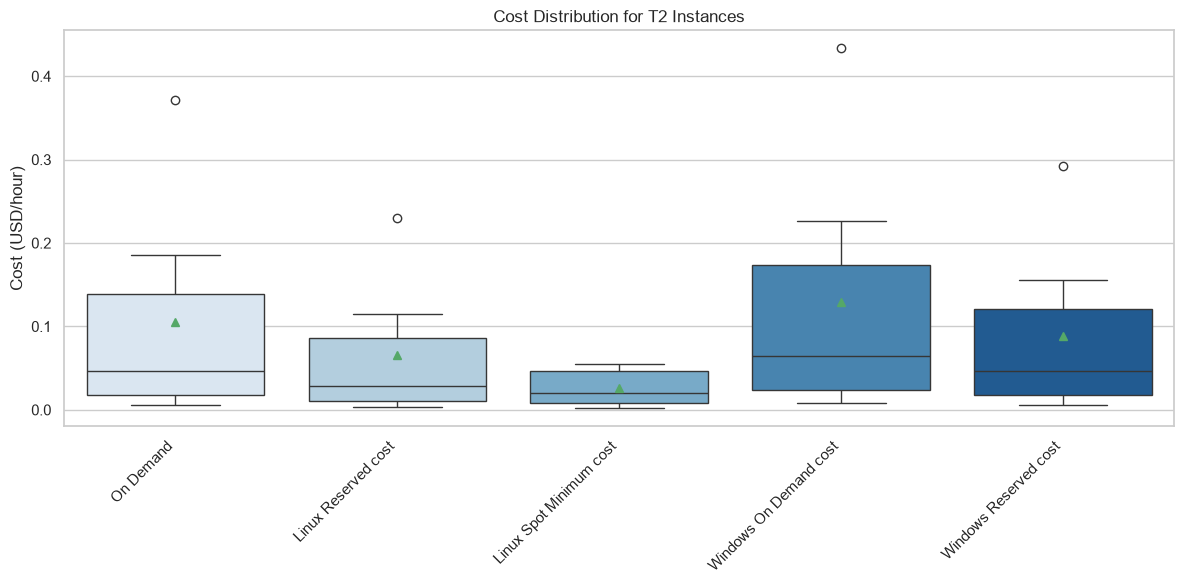

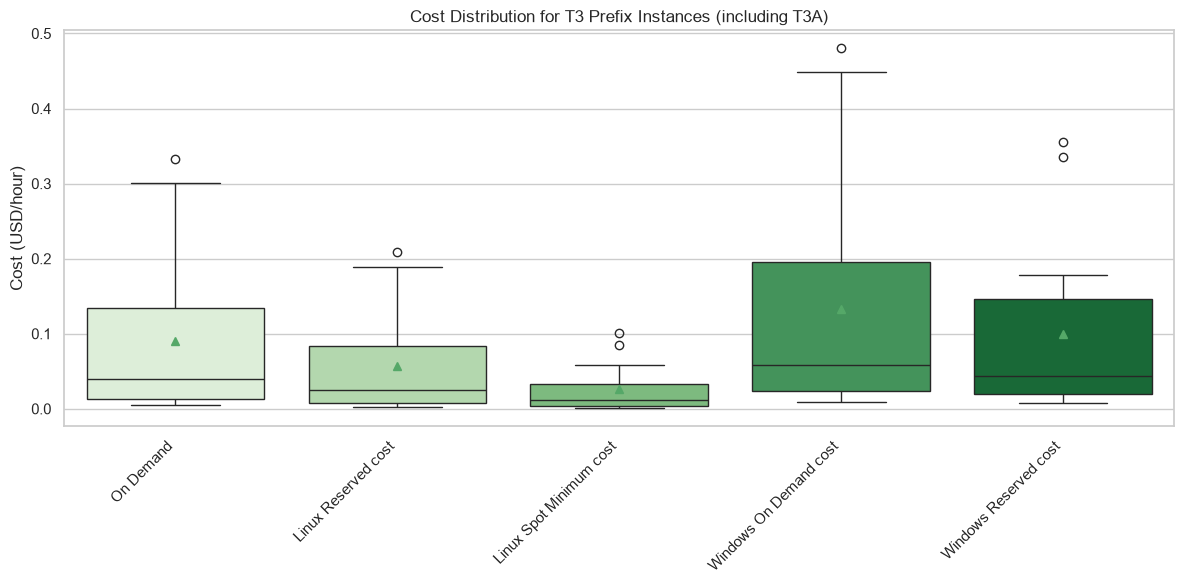

In [11]:
for title, subset, palette in [("T2 Instances", t2_instances, "Blues"),
                               ("T3 Prefix Instances (including T3A)", t3_instances, "Greens")]:
    if subset.empty:
        print(f"No rows for {title}")
        continue
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.boxplot(data=subset[cost_columns], palette=palette, showmeans=True, ax=ax)
    ax.set(title=f"Cost Distribution for {title}", ylabel="Cost (USD/hour)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


In [12]:
comparison = pd.concat([t2_instances[["Name", "On Demand", "Linux Reserved cost"]],
                        t3_instances[["Name", "On Demand", "Linux Reserved cost"]]])
comparison_sorted = comparison.dropna().sort_values("On Demand")
display(comparison_sorted.head(10))
exact_families = data["API Name"].astype("string").str.split(".", regex=False).str[0].str.upper()
exact_comparison = data.loc[exact_families.isin(["T2", "T3"])].copy()
print("Exact T2 and T3 API families (excluding T3A)")
display(exact_comparison[["Name", "API Name", "On Demand", "Linux Reserved cost"]].sort_values("On Demand").head(10))


,Name,On Demand,Linux Reserved cost
1,T3A Nano,0.0047,0.0029
2,T3 Nano,0.0052,0.0033
3,T2 Nano,0.0058,0.0036
5,T3A Micro,0.0094,0.0059
6,T3 Micro,0.0104,0.0065
7,T2 Micro,0.0116,0.0072
9,T3A Small,0.0188,0.0118
11,T3 Small,0.0208,0.013
12,T2 Small,0.023,0.0144
17,T3A Medium,0.0376,0.0236


Exact T2 and T3 API families (excluding T3A)


,Name,API Name,On Demand,Linux Reserved cost
2,T3 Nano,t3.nano,0.0052,0.0033
3,T2 Nano,t2.nano,0.0058,0.0036
6,T3 Micro,t3.micro,0.0104,0.0065
7,T2 Micro,t2.micro,0.0116,0.0072
11,T3 Small,t3.small,0.0208,0.013
12,T2 Small,t2.small,0.023,0.0144
22,T3 Medium,t3.medium,0.0416,0.0261
28,T2 Medium,t2.medium,0.0464,0.0287
51,T3 Large,t3.large,0.0832,0.0522
65,T2 Large,t2.large,0.0928,0.0575


## Part 2 Step 1 — Regression dependencies
The setup cell already checks and installs scikit-learn along with the plotting and data libraries.


In [13]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## Part 2 Step 2 — Reload and clean costs
Reloading keeps the regression data preparation independent of Part 1 transformations.


In [14]:
data = pd.read_csv(file_path)
for column in cost_columns:
    text = data[column].astype("string").str.replace(r"[$,\s]|hourly", "", regex=True)
    data[column] = pd.to_numeric(text, errors="coerce")
data[cost_columns] = data[cost_columns].replace([np.inf, -np.inf], np.nan)
display(data[cost_columns].head())


,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
0,0.0042,0.0026,0.0014,<NA>,<NA>
1,0.0047,0.0029,0.0014,0.0093,0.0075
2,0.0052,0.0033,0.0007,0.0098,0.0079
3,0.0058,0.0036,<NA>,0.0081,0.0059
4,0.0084,0.0053,0.0024,<NA>,<NA>


## Part 2 Step 3 — Engineer numeric features
Strip GiB from memory and extract the CPU count from descriptions that can contain burst-duration text.


In [15]:
data["Instance Memory"] = pd.to_numeric(data["Instance Memory"].astype("string").str.replace(r"\s*GiB\s*", "", regex=True).str.replace(",", "", regex=False), errors="coerce")
data["vCPUs"] = pd.to_numeric(data["vCPUs"].astype("string").str.extract(r"(\d+)", expand=False), errors="coerce")
data[features] = data[features].replace([np.inf, -np.inf], np.nan)
display(data[features].head())


,Instance Memory,vCPUs
0,0.5,2
1,0.5,2
2,0.5,2
3,0.5,1
4,1.0,2


## Part 2 Step 4 — Handle missing values
Drop rows missing On Demand, Instance Memory or vCPUs, or with nonpositive target or feature values. Positive values are required for relative-error weighting. Missing prices in unused columns do not remove a row from training.


In [16]:
data_cleaned = data.dropna(subset=["On Demand", *features]).copy()
data_cleaned = data_cleaned.loc[(data_cleaned["On Demand"] > 0) & (data_cleaned[features] > 0).all(axis=1)]
print(f"Retained {len(data_cleaned)} rows; dropped {len(data) - len(data_cleaned)} rows")
display(data_cleaned.isna().sum().rename("Missing rows").to_frame())
assert data_cleaned[["On Demand", *features]].notna().all().all()
if len(data_cleaned) < 10:
    raise ValueError("At least ten positive complete rows are required for regression.")


Retained 841 rows; dropped 20 rows


,Missing rows
Name,0
API Name,0
Instance Memory,0
vCPUs,0
Instance Storage,0
Network Performance,0
On Demand,0
Linux Reserved cost,4
Linux Spot Minimum cost,19
Windows On Demand cost,243


## Part 2 Step 5 — Split data into 80% training and 20% testing
The features contain only memory and vCPUs. The split uses the assignment's random_state=42.


In [17]:
X = data_cleaned[features]
y = data_cleaned["On Demand"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training samples: {len(X_train)}, testing samples: {len(X_test)}")


Training samples: 672, testing samples: 169


### Choose linear-fit settings using training-only validation
Keep memory and vCPUs as the only features. Compare weight powers 0, 1 and 2, with and without an intercept, using mean absolute percentage error. Each of the five training validation folds learns its own IQR bounds. No test prices are used to select settings. Nonnegative coefficients constrain the slopes; the intercept can still be negative.


In [18]:
FEATURES = features
def select_linear_fit(X, y):
    """Choose linear-fit settings using only training-fold validation prices."""
    candidates = []
    folds = list(KFold(n_splits=min(5, len(X)), shuffle=True, random_state=42).split(X))
    for intercept in [True, False]:
        for power in [0, 1, 2]:
            errors = []
            for train_idx, valid_idx in folds:
                fold_X, fold_y = X.iloc[train_idx], y.iloc[train_idx]
                q1, q3 = fold_y.quantile([0.25, 0.75])
                keep = fold_y.between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
                fold_X, fold_y = fold_X.loc[keep], fold_y.loc[keep]
                weights = (fold_y.median() / fold_y) ** power
                model = LinearRegression(positive=True, fit_intercept=intercept)
                model.fit(fold_X, fold_y, sample_weight=weights)
                predicted = model.predict(X.iloc[valid_idx])
                errors.extend(np.abs(predicted - y.iloc[valid_idx]) / y.iloc[valid_idx])
            candidates.append({"Fit intercept": intercept, "Weight power": power,
                               "CV mean absolute percentage error": float(np.mean(errors) * 100)})
    comparison = pd.DataFrame(candidates).sort_values("CV mean absolute percentage error", ignore_index=True)
    return comparison.iloc[0].to_dict(), comparison



selected, cv_results = select_linear_fit(X_train, y_train)
display(cv_results)
print('Selected:', selected)


,Fit intercept,Weight power,CV mean absolute percentage error
0,True,1,27.005072
1,False,1,29.174424
2,True,2,29.327610
3,False,0,30.103265
4,False,2,33.608731
5,True,0,80.519266


Selected: {'Fit intercept': True, 'Weight power': 1, 'CV mean absolute percentage error': 27.005072367263466}


### Filter training outliers before fitting
Calculate the 1.5 × IQR bounds using only the training target prices. Exclude outliers from training and preserve every test row. This avoids using test data to select training rows. Expensive instances can be legitimate; the filter narrows the model's training coverage.


In [19]:
training_rows_before = len(X_train)
train_q1, train_q3 = y_train.quantile([0.25, 0.75])
train_iqr = train_q3 - train_q1
train_lower = train_q1 - 1.5 * train_iqr
train_upper = train_q3 + 1.5 * train_iqr
training_inliers = y_train.between(train_lower, train_upper)
excluded_training_outliers = data_cleaned.loc[y_train.index[~training_inliers]].copy()
X_train = X_train.loc[training_inliers]
y_train = y_train.loc[training_inliers]
if len(X_train) < 2:
    raise ValueError("Too few training rows remain after outlier filtering.")
print(f"Training IQR bounds: {train_lower:.6f} to {train_upper:.6f} USD/hour")
print(f"Training rows: {training_rows_before} before filtering, {len(X_train)} retained, {len(excluded_training_outliers)} excluded")
print(f"Test rows unchanged: {len(X_test)}")
display(excluded_training_outliers)
filtered_training_data = data_cleaned.loc[X_train.index].copy()
display(filtered_training_data.head())


Training IQR bounds: -5.317875 to 9.753125 USD/hour
Training rows: 672 before filtering, 621 retained, 51 excluded
Test rows unchanged: 169


,Name,API Name,Instance Memory,vCPUs,Instance Storage,Network Performance,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
781,M6IDN 32xlarge,m6idn.32xlarge,512.0,128,7600 GB (4 * 1900 GB NVMe SSD),200 Gigabit,10.1837,6.4157,2.5905,16.0717,12.3037
796,R7IZ Metal-32xl,r7iz.metal-32xl,1024.0,128,EBS only,50 Gigabit,11.904,7.4995,1.5889,17.792,13.3875
831,U-6TB1 112xlarge,u-6tb1.112xlarge,6144.0,448,EBS only,100 Gigabit,54.6,33.647,<NA>,75.208,54.255
816,X8G 48xlarge,x8g.48xlarge,3072.0,192,EBS only,50 Gigabit,18.7584,11.5598,1.9359,<NA>,<NA>
788,I4I 32xlarge,i4i.32xlarge,1024.0,128,30000 GB (8 * 3750 GB NVMe SSD),75 Gigabit,10.9824,7.1266,2.1759,16.8704,13.0146
824,X1E 32xlarge,x1e.32xlarge,3904.0,128,3840 GB (2 * 1920 GB SSD),25 Gigabit,26.688,16.446,2.8576,32.576,22.334
822,X2IEDN 32xlarge,x2iedn.32xlarge,4096.0,128,3800 GB (2 * 1900 GB NVMe SSD),100 Gigabit,26.676,16.4137,3.0098,32.564,22.3017
793,R8G Metal-48xl,r8g.metal-48xl,1536.0,192,EBS only,50 Gigabit,11.3107,7.482,1.4608,<NA>,<NA>
821,TRN1N 32xlarge,trn1n.32xlarge,512.0,128,7600 GB (4 * 1900 GB NVMe SSD),16x 100 Gigabit,24.78,15.2471,3.5642,<NA>,<NA>
797,P3 High Performance GPU Eight Extra Large,p3.8xlarge,244.0,32,EBS only,10 Gigabit,12.24,8.354,4.6905,13.712,9.826


,Name,API Name,Instance Memory,vCPUs,Instance Storage,Network Performance,On Demand,Linux Reserved cost,Linux Spot Minimum cost,Windows On Demand cost,Windows Reserved cost
331,R6G Quadruple Extra Large,r6g.4xlarge,128.0,16,EBS only,Up to 10 Gigabit,0.8064,0.508,0.2421,<NA>,<NA>
362,R6I Quadruple Extra Large,r6i.4xlarge,128.0,16,EBS only,Up to 12.5 Gigabit,1.008,0.6668,0.3779,1.744,1.4028
698,G5 Graphics and Machine Learning GPU 12xlarge,g5.12xlarge,192.0,48,3800 GB NVMe SSD,40 Gigabit,5.672,3.5734,2.2717,7.88,5.7814
774,R7A 32xlarge,r7a.32xlarge,1024.0,128,EBS only,50 Gigabit,9.7376,6.4414,1.4045,15.6256,12.3294
306,D2 Extra Large,d2.xlarge,30.5,4,6144 GB (3 * 2048 GB HDD),Moderate,0.69,0.402,0.0923,0.821,0.472


## Part 2 Step 6 — Train linear regression
The intercept is the fitted price at zero memory and zero CPUs; it is not an actual purchasable instance. Each coefficient describes the fitted price change per feature unit, holding the other feature constant.


In [20]:
original_model = LinearRegression().fit(X_train, y_train)
weights = (y_train.median() / y_train) ** int(selected["Weight power"])
model = LinearRegression(positive=True, fit_intercept=bool(selected["Fit intercept"]))
model.fit(X_train, y_train, sample_weight=weights)
print(f"Intercept: {model.intercept_}")
coefficients = pd.Series(model.coef_, index=features, name="Coefficient")
display(coefficients.to_frame())


Intercept: -0.01887336918237001


,Coefficient
Instance Memory,0.004508
vCPUs,0.035455


## Part 2 Step 7 — Evaluate on the held-out test set
MAE and RMSE use USD/hour. MSE uses squared USD/hour. R² is included as an additional fit measure and is unitless.


In [21]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r_squared = r2_score(y_test, y_pred)
print(f"Mean Absolute Error (MAE): {mae:.6f}")
print(f"Mean Squared Error (MSE): {mse:.6f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.6f}")
print(f"R²: {r_squared:.6f}")
predictions = data_cleaned.loc[X_test.index, ["Name", "API Name", *features]].copy()
predictions["Actual USD/hour"] = y_test
predictions["Predicted USD/hour"] = y_pred
predictions["Original fit USD/hour"] = original_model.predict(X_test)
predictions["Residual USD/hour"] = y_test - y_pred
predictions["Absolute error USD/hour"] = np.abs(y_test - y_pred)
predictions["Absolute error percent"] = 100 * np.abs(y_test - y_pred) / y_test
display(predictions.head(10))


Mean Absolute Error (MAE): 3.092436
Mean Squared Error (MSE): 273.111000
Root Mean Squared Error (RMSE): 16.526070
R²: 0.743343


,Name,API Name,Instance Memory,vCPUs,Actual USD/hour,Predicted USD/hour,Original fit USD/hour,Residual USD/hour,Absolute error USD/hour,Absolute error percent
485,C6G 16xlarge,c6g.16xlarge,128.0,64,2.176,2.827277,2.950345,-0.651277,0.651277,29.930009
817,X8G Metal-48xl,x8g.metal-48xl,3072.0,192,18.7584,20.636674,20.131825,-1.878274,1.878274,10.012974
30,A1 Large,a1.large,4.0,2,0.051,0.070069,0.235457,-0.019069,0.019069,37.389862
551,M6GD 16xlarge,m6gd.16xlarge,256.0,64,2.8928,3.404282,3.501609,-0.511482,0.511482,17.681193
96,R5AD Large,r5ad.large,16.0,2,0.131,0.124163,0.287138,0.006837,0.006837,5.219078
244,C3 High-CPU Double Extra Large,c3.2xlarge,15.0,8,0.42,0.332388,0.493881,0.087612,0.087612,20.860101
559,R6I 12xlarge,r6i.12xlarge,384.0,48,3.024,3.414000,3.490073,-0.39,0.39,12.896815
352,R8G Quadruple Extra Large,r8g.4xlarge,128.0,16,0.9426,1.125418,1.261944,-0.182818,0.182818,19.39504
465,D3 Quadruple Extra Large,d3.4xlarge,128.0,16,1.998,1.125418,1.261944,0.872582,0.872582,43.67279
544,M7A 12xlarge,m7a.12xlarge,192.0,48,2.7821,2.548493,2.663177,0.233607,0.233607,8.396793


### Compare the selected fit with the original on actual held-out prices
Both fits use the same filtered training rows and all 169 test rows. Within 20 percent is an illustrative count, not a correctness guarantee. Inspect the actual prices and largest errors as well as averages.


In [22]:
def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    percent_error = 100 * np.abs(np.asarray(predicted) - np.asarray(actual)) / np.asarray(actual)
    return {"MAE": mean_absolute_error(actual, predicted), "MSE": mse,
            "RMSE": float(np.sqrt(mse)), "R²": r2_score(actual, predicted),
            "Median absolute percentage error": float(np.median(percent_error)),
            "Mean absolute percentage error": float(np.mean(percent_error)),
            "Within 20 percent": int(np.count_nonzero(percent_error <= 20))}



comparison_metrics = pd.DataFrame([regression_metrics(y_test, original_model.predict(X_test)), regression_metrics(y_test, y_pred)], index=['Original unweighted fit', 'Selected weighted fit'])
display(comparison_metrics)
display(predictions.sort_values('Actual USD/hour').head(10))
display(predictions.nlargest(10, 'Absolute error percent'))


,MAE,MSE,RMSE,R²,Median absolute percentage error,Mean absolute percentage error,Within 20 percent
Original unweighted fit,3.203530,291.8741,17.084323,0.725710,24.160915,101.735088,73
Selected weighted fit,3.092436,273.1110,16.526070,0.743343,16.919874,30.241846,93


,Name,API Name,Instance Memory,vCPUs,Actual USD/hour,Predicted USD/hour,Original fit USD/hour,Residual USD/hour,Absolute error USD/hour,Absolute error percent
2,T3 Nano,t3.nano,0.5,2,0.0052,0.054291,0.220383,-0.049091,0.049091,944.064631
5,T3A Micro,t3a.micro,1.0,2,0.0094,0.056545,0.222537,-0.047145,0.047145,501.545584
7,T2 Micro,t2.micro,1.0,1,0.0116,0.021090,0.187362,-0.00949,0.00949,81.809327
10,T1 Micro,t1.micro,0.613,1,0.02,0.019345,0.185695,0.000655,0.000655,3.273276
23,C6GN Medium,c6gn.medium,2.0,1,0.0432,0.025598,0.191668,0.017602,0.017602,40.745995
29,R6G Medium,r6g.medium,8.0,1,0.0504,0.052645,0.217509,-0.002245,0.002245,4.454007
30,A1 Large,a1.large,4.0,2,0.051,0.070069,0.235457,-0.019069,0.019069,37.389862
31,C7A Medium,c7a.medium,2.0,1,0.0513,0.025598,0.191668,0.025702,0.025702,50.101891
33,R7G Medium,r7g.medium,8.0,1,0.0536,0.052645,0.217509,0.000955,0.000955,1.782053
39,T4G Large,t4g.large,8.0,2,0.0672,0.088100,0.252684,-0.0209,0.0209,31.101521


,Name,API Name,Instance Memory,vCPUs,Actual USD/hour,Predicted USD/hour,Original fit USD/hour,Residual USD/hour,Absolute error USD/hour,Absolute error percent
2,T3 Nano,t3.nano,0.5,2,0.0052,0.054291,0.220383,-0.049091,0.049091,944.064631
5,T3A Micro,t3a.micro,1.0,2,0.0094,0.056545,0.222537,-0.047145,0.047145,501.545584
7,T2 Micro,t2.micro,1.0,1,0.0116,0.021090,0.187362,-0.00949,0.00949,81.809327
360,G5 Graphics and Machine Learning GPU Extra Large,g5.xlarge,16.0,4,1.006,0.195074,0.357488,0.810926,0.810926,80.608965
827,P3DN 24xlarge,p3dn.24xlarge,768.0,96,31.212,6.846873,6.832267,24.365127,24.365127,78.063332
328,G6 Graphics and Machine Learning GPU Extra Large,g6.xlarge,16.0,4,0.8048,0.195074,0.357488,0.609726,0.609726,75.761206
828,P4D Highest Performance GPU 24xlarge,p4d.24xlarge,1152.0,96,32.7726,8.577886,8.486060,24.194714,24.194714,73.826042
558,G6E Quadruple Extra Large,g6e.4xlarge,128.0,16,3.0042,1.125418,1.261944,1.878782,1.878782,62.538524
405,D2 Double Extra Large,d2.2xlarge,61.0,8,1.38,0.539749,0.691992,0.840251,0.840251,60.887783
477,D3EN Quadruple Extra Large,d3en.4xlarge,64.0,16,2.103,0.836915,0.986312,1.266085,1.266085,60.203739


## Part 2 Step 8 — Plot actual versus predicted prices
The dashed red line indicates perfect predictions. Negative model outputs are shown as fitted, rather than silently changed.


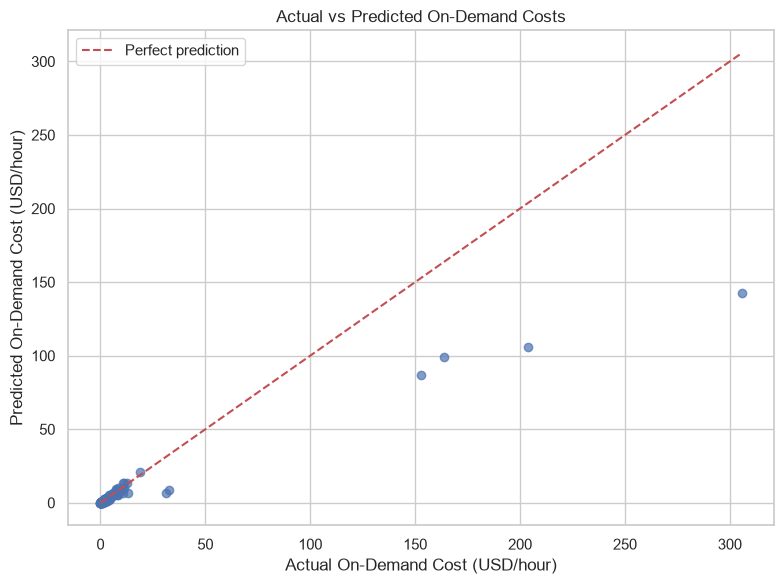

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred, alpha=0.7, color="b")
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
ax.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
ax.set(title="Actual vs Predicted On-Demand Costs", xlabel="Actual On-Demand Cost (USD/hour)", ylabel="Predicted On-Demand Cost (USD/hour)")
ax.legend()
plt.tight_layout()
plt.show()


## Part 2 Step 9 — Predict a new configuration
The default is the activity's 4 GiB, 2 vCPU example. Edit these two values and rerun this cell for another configuration.


In [24]:
new_memory_gib = 4.0
new_vcpus = 2
if new_memory_gib <= 0 or new_vcpus < 1 or int(new_vcpus) != new_vcpus:
    raise ValueError("Memory must be positive and vCPUs must be a positive integer.")
new_instance = pd.DataFrame([[new_memory_gib, new_vcpus]], columns=features)
predicted_cost = float(model.predict(new_instance)[0])
print(f"Predicted On-Demand Cost for {new_memory_gib:g} GiB, {new_vcpus} vCPUs: ${predicted_cost:.4f}/hour")
if predicted_cost < 0:
    print("This negative output is not a valid price. The fitted model is unsuitable for this configuration.")
if any(new_instance[col].iloc[0] < X_train[col].min() or new_instance[col].iloc[0] > X_train[col].max() for col in features):
    print("This configuration is outside the training range; the prediction is an extrapolation.")


Predicted On-Demand Cost for 4 GiB, 2 vCPUs: $0.0701/hour


### Interpreting the regression
Memory and vCPUs capture only part of the variation in EC2 pricing. The activity's
linear model omits instance family, architecture, region and storage/network attributes.
The selected weighted fit uses only memory and vCPUs, preserving the linear model.
Multiple families can share those two inputs yet have different prices, so this model
cannot predict a unique correct price for every instance. Training excludes cost outliers selected using training-only IQR bounds. Evaluation
retains all test instances, so errors also measure predictions for expensive instances
outside the retained training prices. Use the held-out errors to judge its fit. Predictions are
educational model estimates rather than AWS quotes. A negative prediction indicates
that the fitted relationship is unsuitable for that configuration.
